## 2. Feature Engineering

Input: per-station daily ride counts, MinMax scaled to [0, 1]. Single channel — no calendar features.

## 1. Setup & Data Prep

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import clear_output
from dotenv import load_dotenv
from sklearn.preprocessing import MinMaxScaler
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

from divvy_demand.infra.s3_client import S3Client

load_dotenv('../../.env')
s3 = S3Client(env='prod')

station = s3.read_processed('station')
station['date'] = pd.to_datetime(station['date'])
print('Station table:', station.shape)
station.head()

Station table: (1404660, 7)


,date,start_station_name,start_station_id,total_rides,ebike_rides,member_rides,casual_rides
0,2020-01-01,63rd St Beach,101,2,0,2,0
1,2020-01-01,900 W Harrison St,109,1,0,1,0
2,2020-01-01,Aberdeen St & Jackson Blvd,21,2,0,2,0
3,2020-01-01,Aberdeen St & Monroe St,80,7,0,7,0
4,2020-01-01,Aberdeen St & Randolph St,621,3,0,3,0


In [10]:
YEARS = [
    # 2020, 
    # 2021, 
    2023
    ]

raw_pivots = []
for yr in YEARS:
    df_yr = station[station['date'].dt.year == yr].copy()
    p = (
        df_yr.groupby(['start_station_name', 'date'])['total_rides']
        .sum()
        .unstack('date')
        .fillna(0)
    )
    raw_pivots.append(p)

n_days = min(p.shape[1] for p in raw_pivots)
print(f'Aligning all years to {n_days} days')

pivots = []
for yr, p in zip(YEARS, raw_pivots):
    p = p.iloc[:, :n_days]
    p.columns = range(n_days)
    p.index = [f'{s}  [{yr}]' for s in p.index]
    pivots.append(p)

pivot_full = pd.concat(pivots, axis=0)
print(f'All stations x years: {pivot_full.shape[0]}, Days: {pivot_full.shape[1]}')
print(f'NaN count: {pivot_full.isna().sum().sum()}')

Aligning all years to 365 days
All stations x years: 1593, Days: 365
NaN count: 0


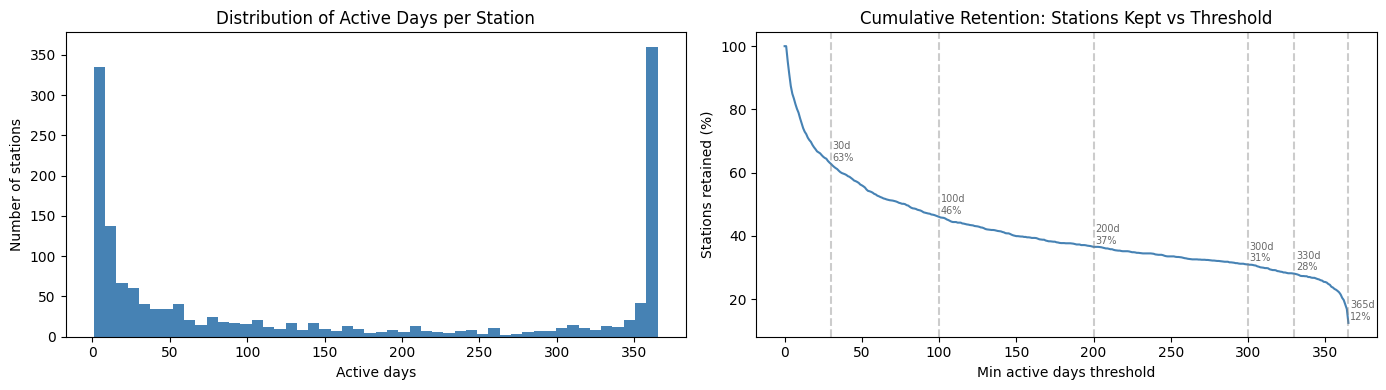


Decile breakdown:
  P  0: 1 active days
  P 10: 3 active days
  P 20: 8 active days
  P 30: 16 active days
  P 40: 36 active days
  P 50: 78 active days
  P 60: 149 active days
  P 70: 308 active days
  P 80: 361 active days
  P 90: 365 active days
  P100: 365 active days


In [11]:
# Active days distribution + cumulative retention curve
active_days_all = (pivot_full > 0).sum(axis=1).sort_values()
n_total = len(active_days_all)

thresholds = np.arange(0, pivot_full.shape[1] + 1, 1)
pct_kept = [(active_days_all >= t).sum() / n_total * 100 for t in thresholds]

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Left: histogram
axes[0].hist(active_days_all.values, bins=50, color='steelblue', edgecolor='none')
axes[0].set_xlabel('Active days')
axes[0].set_ylabel('Number of stations')
axes[0].set_title('Distribution of Active Days per Station')

# Right: cumulative retention curve (% stations kept vs threshold)
axes[1].plot(thresholds, pct_kept, color='steelblue')
axes[1].set_xlabel('Min active days threshold')
axes[1].set_ylabel('Stations retained (%)')
axes[1].set_title('Cumulative Retention: Stations Kept vs Threshold')

# Mark some reference lines
for t in [30, 100, 200, 300, 330, 365]:
    pct = (active_days_all >= t).sum() / n_total * 100
    axes[1].axvline(t, color='gray', linestyle='--', alpha=0.4)
    axes[1].text(t + 1, pct + 1, f'{t}d\n{pct:.0f}%', fontsize=7, color='dimgray')

plt.tight_layout()
plt.show()

# Decile table
print('\nDecile breakdown:')
for d in range(0, 11):
    q = np.percentile(active_days_all, d * 10)
    print(f'  P{d*10:3d}: {q:.0f} active days')

In [12]:
# No active-days filtering — use all stations
pivot = pivot_full
dates = pivot.columns
print(f'Stations: {len(pivot)}  |  Days: {pivot.shape[1]}')


Stations: 1593  |  Days: 365


## 2. Feature Engineering

In [13]:
# MinMax scale each station to [0, 1]
rides_scaled = MinMaxScaler().fit_transform(pivot.T).T  # (n_stations, n_days)

X = rides_scaled[:, None, :].astype('float32')  # (n_stations, 1, n_days)

n_stations, n_days = pivot.shape
dates = pivot.columns

print(f"X shape: {X.shape}  — (stations, 1, days)")
print(f"Ride count range: [{X.min():.3f}, {X.max():.3f}]")

X shape: (1593, 1, 365)  — (stations, 1, days)
Ride count range: [0.000, 1.000]


In [14]:
import re

# Load station coordinates
raw_frames = []
for month in [3, 6, 9]:
    raw = s3.read_raw(2023, month)
    raw_frames.append(raw[['start_station_name', 'start_lat', 'start_lng']].dropna())
coords_raw = pd.concat(raw_frames, ignore_index=True)
station_coords = (
    coords_raw.groupby('start_station_name')[['start_lat', 'start_lng']]
    .mean()
    .reset_index()
)

# Strip year tag from pivot index to match station_coords keys
base_names = [re.sub(r'\s+\[\d{4}\]$', '', n) for n in pivot.index]
coords_df = pd.DataFrame({'start_station_name': base_names}).merge(
    station_coords, on='start_station_name', how='left'
)

lat_min, lat_max = station_coords['start_lat'].min(), station_coords['start_lat'].max()
lng_min, lng_max = station_coords['start_lng'].min(), station_coords['start_lng'].max()

lat_norm = (coords_df['start_lat'].fillna(station_coords['start_lat'].mean()) - lat_min) / (lat_max - lat_min)
lng_norm = (coords_df['start_lng'].fillna(station_coords['start_lng'].mean()) - lng_min) / (lng_max - lng_min)

coords_array = np.stack([lat_norm.values, lng_norm.values], axis=1).astype(np.float32)
coords_tensor_all = torch.tensor(coords_array)  # (n_stations, 2)

missing = coords_df['start_lat'].isna().sum()
print(f'Coords loaded: {len(coords_df)} stations, {missing} missing (filled with mean)')
print(f'coords_tensor shape: {tuple(coords_tensor_all.shape)}')

Coords loaded: 1593 stations, 168 missing (filled with mean)
coords_tensor shape: (1593, 2)


In [15]:
# Train / val split — hold out 20% of stations
np.random.seed(42)
idx = np.random.permutation(n_stations)
split = int(0.8 * n_stations)
train_idx, val_idx = idx[:split], idx[split:]

X_tensor = torch.tensor(X, dtype=torch.float32)
X_train = X_tensor[train_idx]
X_val   = X_tensor[val_idx]

coords_train = coords_tensor_all[train_idx]
coords_val   = coords_tensor_all[val_idx]

train_loader = DataLoader(TensorDataset(X_train, coords_train), batch_size=64, shuffle=True)
val_loader   = DataLoader(TensorDataset(X_val,   coords_val),   batch_size=64, shuffle=False)

print(f'Train: {len(X_train)} stations | Val: {len(X_val)} stations')

Train: 1274 stations | Val: 319 stations


## 3. Model Architecture

In [ ]:
import math
import torch.nn.functional as F

N_FEATURES      = X.shape[1]  # 1
SEQ_LEN         = X.shape[2]  # 365
LATENT_CHANNELS = 3


class InceptionBlock1D(nn.Module):
    KERNELS = [2, 3, 4, 5, 6, 7, 14, 21, 30, 60, 91]

    def __init__(self, in_channels, out_per_branch):
        super().__init__()
        self.branches = nn.ModuleList([
            nn.Sequential(
                nn.Conv1d(in_channels, out_per_branch, kernel_size=k, padding=k // 2),
                nn.BatchNorm1d(out_per_branch),
                nn.ReLU(),
            )
            for k in self.KERNELS
        ])
        out_channels = out_per_branch * len(self.KERNELS)
        self.residual_proj = nn.Conv1d(in_channels, out_channels, kernel_size=1)

    def forward(self, x):
        outs = [b(x) for b in self.branches]
        min_len = min(o.shape[-1] for o in outs)
        out = torch.cat([o[..., :min_len] for o in outs], dim=1)
        res = self.residual_proj(x)[..., :min_len]
        return out + res


class CNNAutoencoder(nn.Module):
    def __init__(self, n_features, seq_len, latent_channels=3):
        super().__init__()
        self.seq_len = seq_len
        self.latent_channels = latent_channels
        enc1_out = 8 * len(InceptionBlock1D.KERNELS)  # 88

        # Encoder
        self.enc1     = InceptionBlock1D(n_features, 8)               # (  1, T) -> (88, T)
        self.enc2     = nn.Sequential(
            nn.Conv1d(enc1_out, 64, kernel_size=7, padding=3),
            nn.BatchNorm1d(64), nn.ReLU(),
        )                                                              # (88, T) -> (64, T)
        self.enc3     = nn.Sequential(
            nn.Conv1d(64, 32, kernel_size=7, padding=3),
            nn.BatchNorm1d(32), nn.ReLU(),
        )                                                              # (64, T) -> (32, T)
        self.enc4     = nn.Sequential(
            nn.Conv1d(32, 16, kernel_size=7, padding=3),
            nn.BatchNorm1d(16), nn.ReLU(),
        )                                                              # (32, T) -> (16, T)
        self.enc_proj = nn.Conv1d(16, latent_channels, kernel_size=1) # (16, T) -> ( C, T)
        self.pool     = nn.Conv1d(latent_channels, latent_channels, kernel_size=7, stride=4,
                                  padding=3, groups=latent_channels)  # (C, T) -> (C, T/4)

        # Compute T_latent analytically (kernel=7, stride=4, padding=3)
        self.latent_t = (seq_len - 1) // 4 + 1                       # e.g. 92 for seq_len=365
        flat_in = latent_channels * self.latent_t + 2                 # C*T_latent + 2 (lat/lon)

        # Decoder — linear mixes flat latent+coords back to conv shape
        self.dec_proj = nn.Linear(flat_in, 16 * self.latent_t)        # (C*T+2) -> (16*T)
        self.dec1     = nn.Sequential(
            nn.Conv1d(16, 32, kernel_size=7, padding=3), nn.ReLU(),
        )                                                              # (16, T/4) -> (32, T/4)
        self.dec2     = nn.Sequential(
            nn.Conv1d(32, 64, kernel_size=7, padding=3), nn.ReLU(),
        )                                                              # (32, T/4) -> (64, T/4)
        self.decoder_conv = nn.Sequential(
            nn.Upsample(size=seq_len),                                 # (64, T/4) -> (64, T)
            nn.Conv1d(64, enc1_out, kernel_size=7, padding=3), nn.ReLU(),
            nn.Conv1d(enc1_out, n_features, kernel_size=3, padding=1), nn.Sigmoid(),
        )                                                              # -> (1, T)

    def encode(self, x, coords):
        """Returns flat (B, C*T_latent + 2) — temporal latent + lat/lon."""
        z = self.pool(self.enc_proj(self.enc4(self.enc3(self.enc2(self.enc1(x))))))
        z_flat = z.reshape(z.shape[0], -1)                            # (B, C*T_latent)
        return torch.cat([z_flat, coords], dim=1)                     # (B, C*T_latent + 2)

    def decode(self, z_flat):
        h = self.dec_proj(z_flat)                                     # (B, 16*T_latent)
        h = h.reshape(h.shape[0], 16, self.latent_t)                  # (B, 16, T_latent)
        return self.decoder_conv(self.dec2(self.dec1(h)))

    def forward(self, x, coords):
        return self.decode(self.encode(x, coords))


model = CNNAutoencoder(N_FEATURES, SEQ_LEN, LATENT_CHANNELS)
with torch.no_grad():
    dummy        = torch.zeros(2, N_FEATURES, SEQ_LEN)
    dummy_coords = torch.zeros(2, 2)
    z   = model.encode(dummy, dummy_coords)
    out = model.decode(z)
    print(f'Input:   {tuple(dummy.shape)}')
    print(f'Latent:  {tuple(z.shape)}  -- {LATENT_CHANNELS*model.latent_t} temporal + 2 coords')
    print(f'Output:  {tuple(out.shape)}  {"ok" if out.shape == dummy.shape else "mismatch"}')
    print(f'Params:  {sum(p.numel() for p in model.parameters()):,}')

## 4. Training (live loss plot)

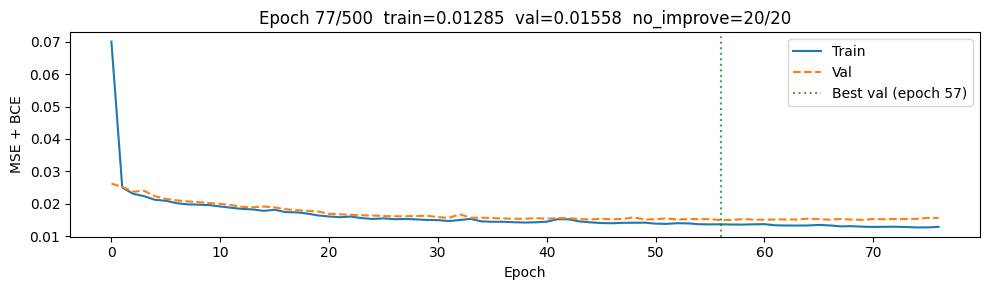

Early stopping at epoch 77 — no val improvement for 20 epochs
Restored best model (val=0.014929)


In [17]:
EPOCHS    = 500
LR        = 1e-3
PATIENCE  = 20
MIN_DELTA = 1e-7
BCE_WEIGHT = 0.01

device = torch.device('mps' if torch.backends.mps.is_available() else 'cpu')
print(f'Device: {device}')

model = CNNAutoencoder(N_FEATURES, SEQ_LEN, LATENT_CHANNELS).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=LR)

def combined_loss(pred, target):
    mse = torch.nn.functional.mse_loss(pred, target)
    is_open = (target > 0).float()
    bce = torch.nn.functional.binary_cross_entropy(pred.clamp(1e-6, 1 - 1e-6), is_open)
    return mse + BCE_WEIGHT * bce

train_losses, val_losses = [], []
best_val   = float('inf')
best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
no_improve = 0

for epoch in range(1, EPOCHS + 1):
    # --- train ---
    model.train()
    t_loss = 0
    for batch, coords in train_loader:
        batch, coords = batch.to(device), coords.to(device)
        loss = combined_loss(model(batch, coords), batch)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        t_loss += loss.item() * len(batch)
    train_losses.append(t_loss / len(X_train))

    # --- val ---
    model.eval()
    v_loss = 0
    with torch.no_grad():
        for batch, coords in val_loader:
            batch, coords = batch.to(device), coords.to(device)
            v_loss += combined_loss(model(batch, coords), batch).item() * len(batch)
    val_losses.append(v_loss / len(X_val))

    # --- early stopping ---
    if val_losses[-1] < best_val - MIN_DELTA:
        best_val   = val_losses[-1]
        best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
        no_improve = 0
    else:
        no_improve += 1

    # --- live plot every 5 epochs ---
    if epoch % 5 == 0 or epoch == 1 or no_improve == PATIENCE:
        clear_output(wait=True)
        fig, ax = plt.subplots(figsize=(10, 3))
        ax.plot(train_losses, label='Train')
        ax.plot(val_losses,   label='Val', linestyle='--')
        ax.axvline(len(val_losses) - no_improve - 1, color='green',
                   linestyle=':', alpha=0.7, label=f'Best val (epoch {len(val_losses)-no_improve})')
        ax.set_xlabel('Epoch')
        ax.set_ylabel('MSE + BCE')
        ax.set_title(f'Epoch {epoch}/{EPOCHS}  train={train_losses[-1]:.5f}  val={val_losses[-1]:.5f}  no_improve={no_improve}/{PATIENCE}')
        ax.legend()
        plt.tight_layout()
        plt.show()

    if no_improve >= PATIENCE:
        print(f'Early stopping at epoch {epoch} — no val improvement for {PATIENCE} epochs')
        break

model.load_state_dict(best_state)
print(f'Restored best model (val={best_val:.6f})')

## 5. Reconstruction Check

In [18]:
model.eval()
coords_dev = coords_tensor_all.to(device)
with torch.no_grad():
    X_recon    = model(X_tensor.to(device), coords_dev).cpu().numpy()
    Z_full     = model.encode(X_tensor.to(device), coords_dev).cpu().numpy()  # (n_stations, C+2, T_latent)

Z_temporal = Z_full[:, :LATENT_CHANNELS, :]   # temporal channels only — used for clustering
Z          = Z_temporal.reshape(len(Z_temporal), -1)

recon_error = np.mean((X[:, 0, :] - X_recon[:, 0, :]) ** 2, axis=1)
print(f'Mean ride-channel MSE: {recon_error.mean():.5f}')
print(f'\nWorst 5 stations:')
for i in np.argsort(recon_error)[-5:][::-1]:
    print(f'  {pivot.index[i]}: {recon_error[i]:.5f}')

Mean ride-channel MSE: 0.00782

Worst 5 stations:
  Kedzie Ave & 52nd St  [2023]: 0.03648
  Calumet Ave & 71st St  [2023]: 0.03447
  Public Rack - Christiana Ave & Belmont Ave  [2023]: 0.03329
  Public Rack - Western Ave & 92nd Pl  [2023]: 0.02978
  Public Rack - Kildare Ave & Washignton Blvd  [2023]: 0.02965


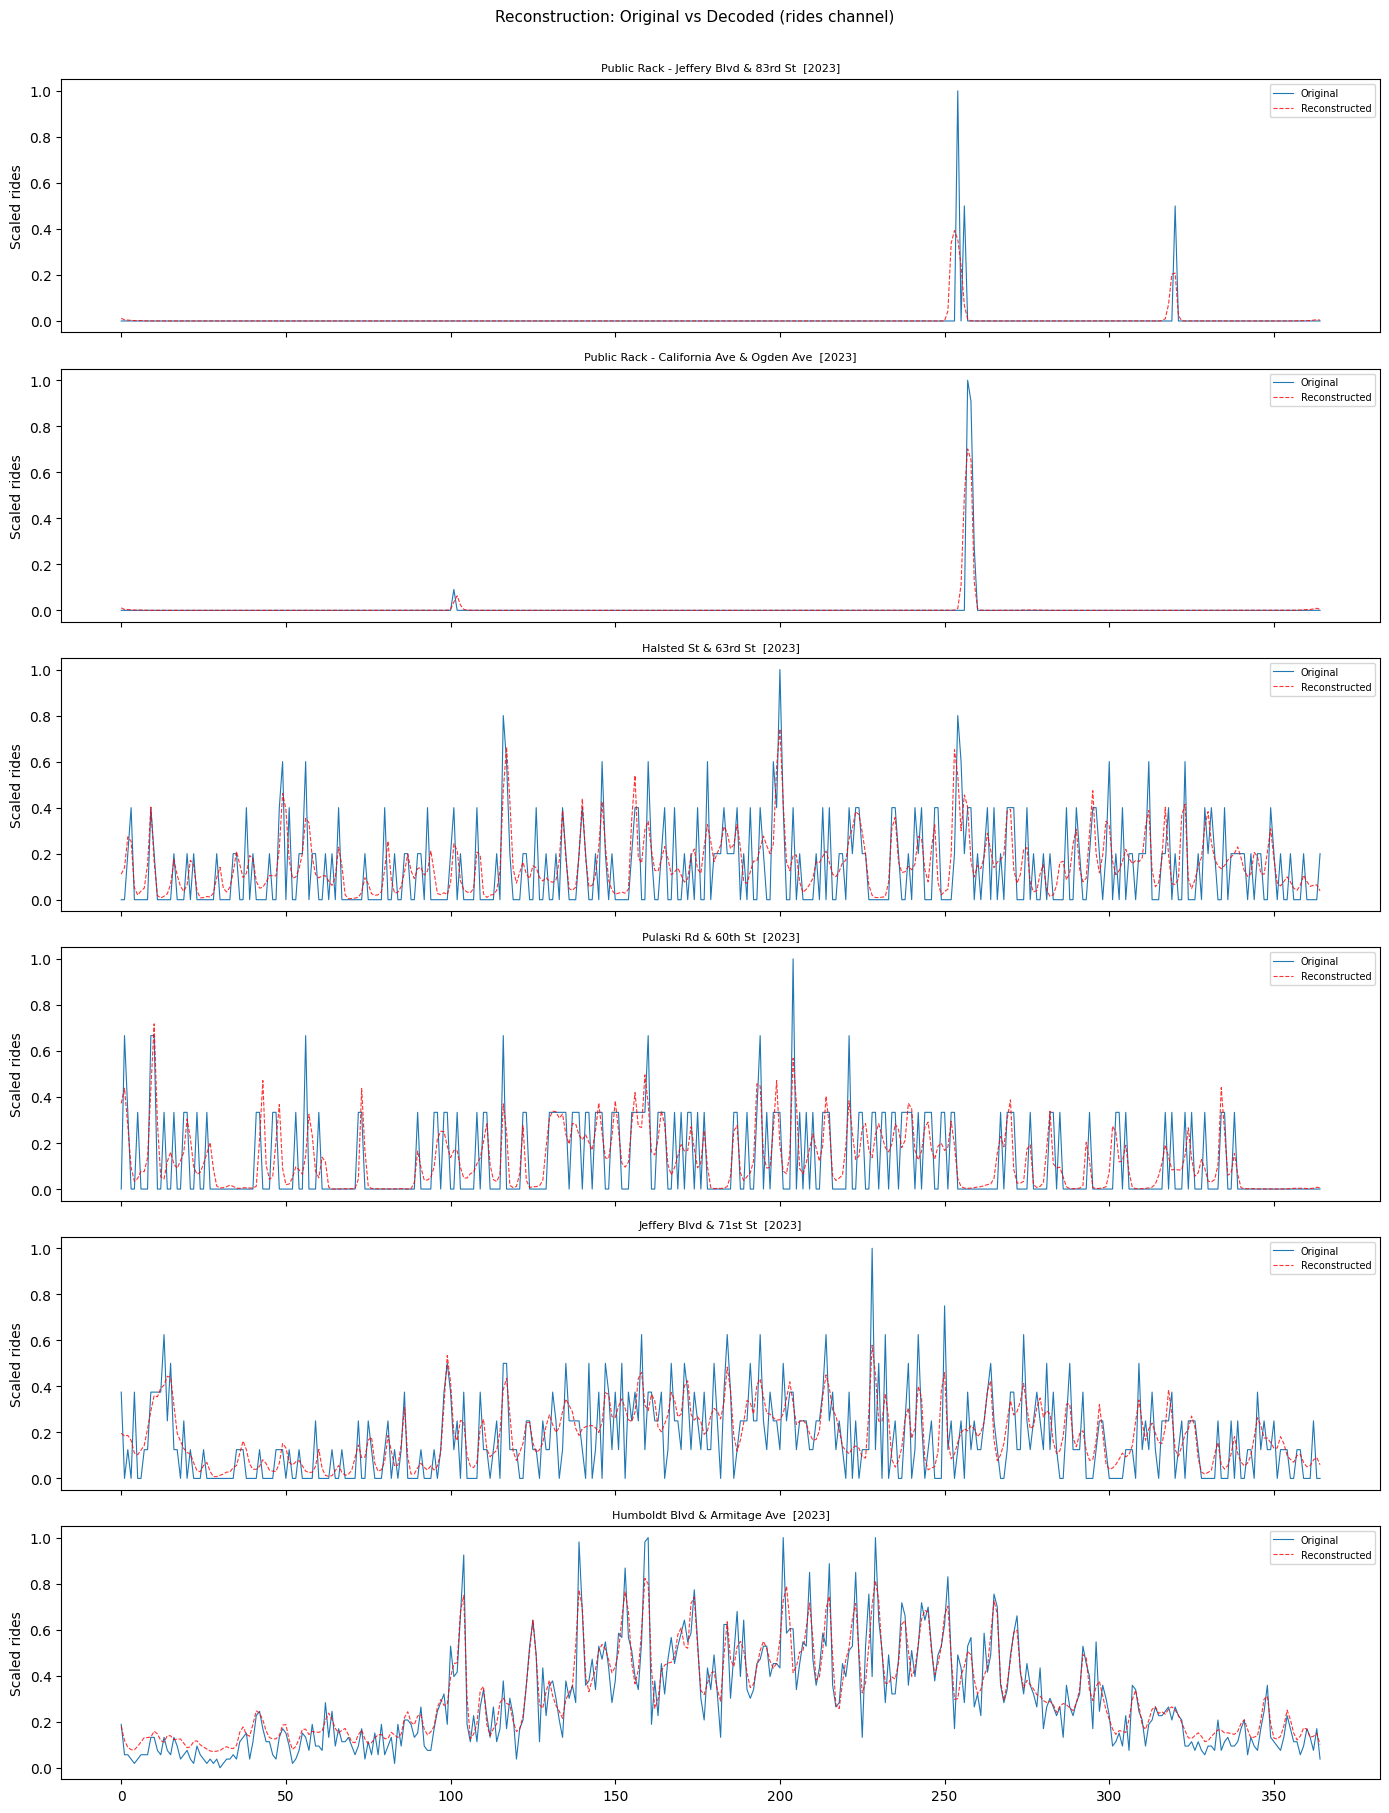

In [19]:
# Plot original vs reconstruction — rides channel — 6 random stations
np.random.seed(0)
sample_idx = np.random.choice(n_stations, 6, replace=False)

fig, axes = plt.subplots(6, 1, figsize=(14, 18), sharex=True)
for ax, idx in zip(axes, sample_idx):
    ax.plot(dates, X[idx, 0, :], label='Original', linewidth=0.8)
    ax.plot(dates, X_recon[idx, 0, :], label='Reconstructed', linewidth=0.8,
            linestyle='--', color='red', alpha=0.8)
    ax.set_title(pivot.index[idx], fontsize=8)
    ax.set_ylabel('Scaled rides')
    ax.legend(fontsize=7)
fig.suptitle('Reconstruction: Original vs Decoded (rides channel)', fontsize=11, y=1.005)
plt.tight_layout()
plt.show()

## 6. Latent Space — Clustering & t-SNE

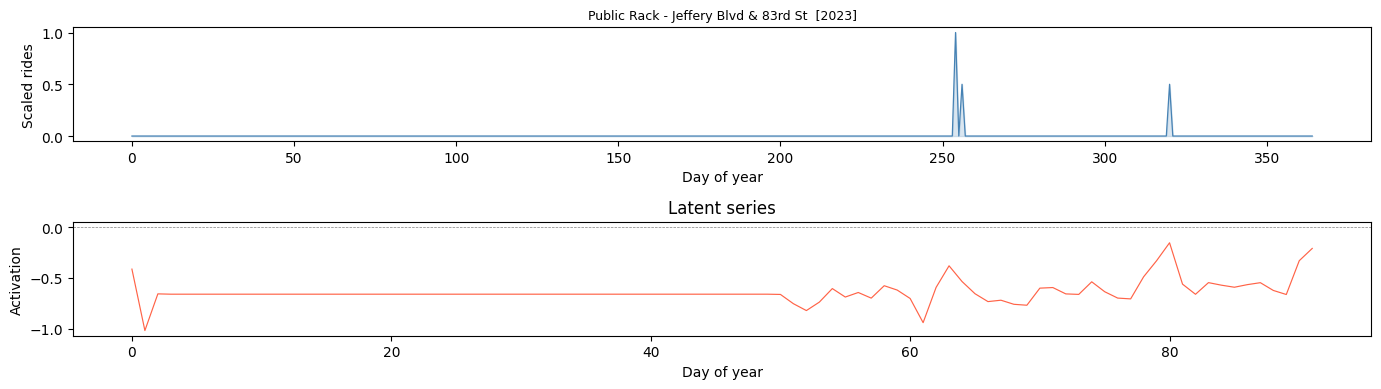

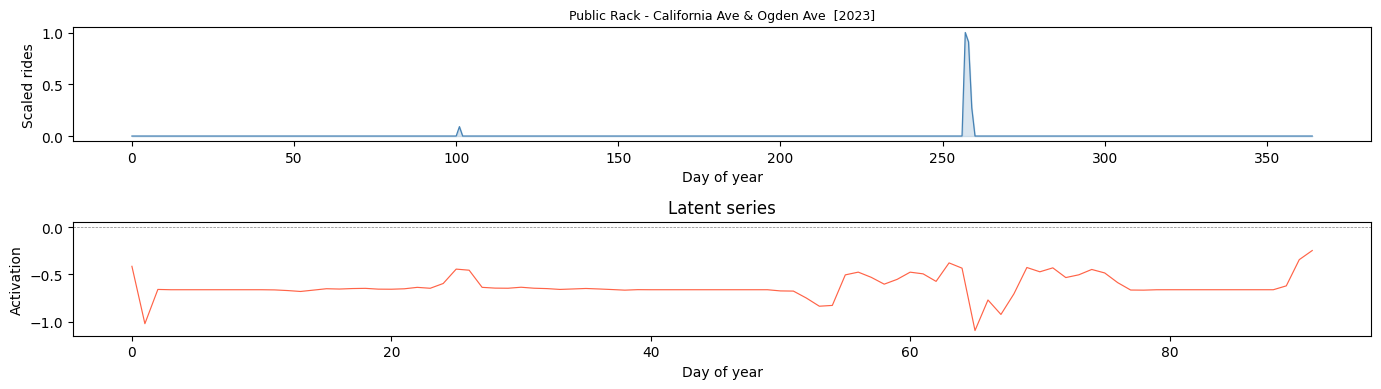

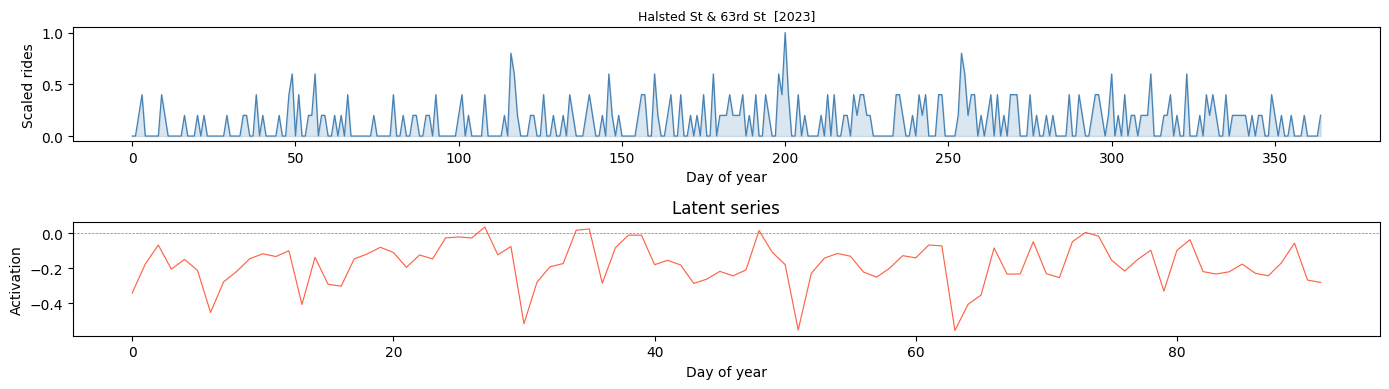

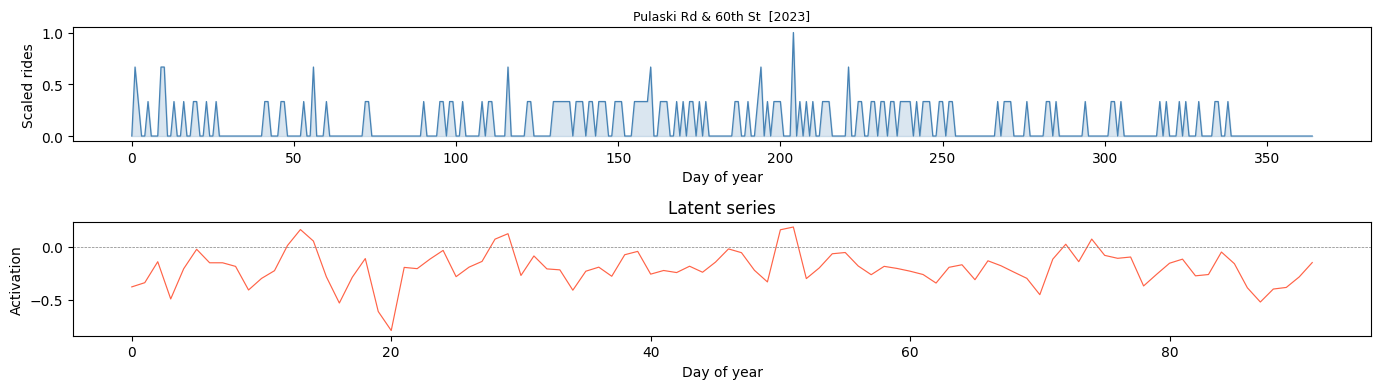

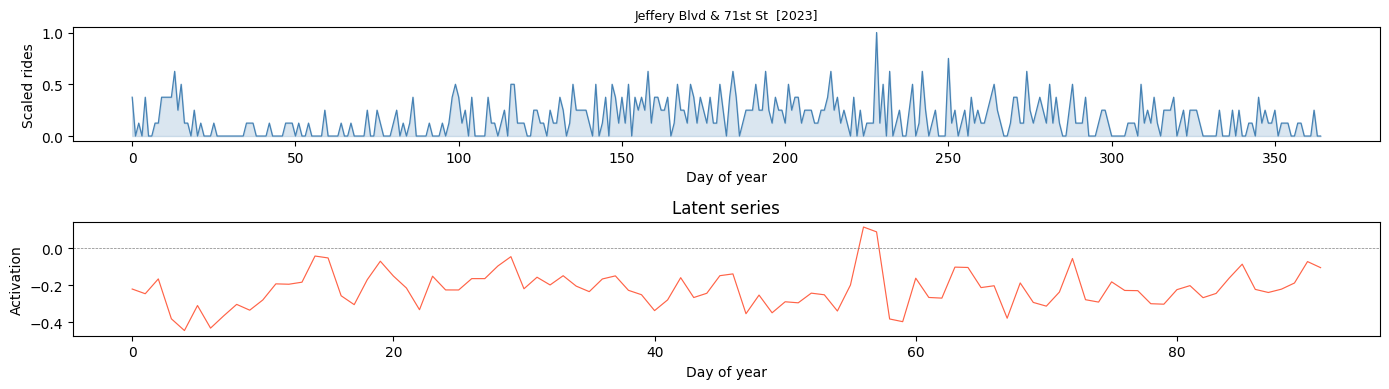

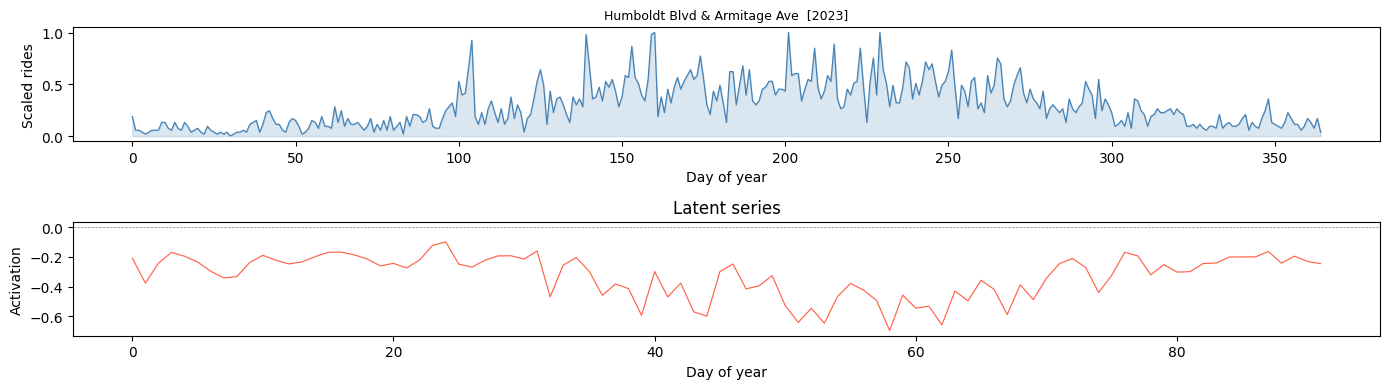

In [20]:
# Latent series — same 6 stations as reconstruction plot above
np.random.seed(0)
sample_idx = np.random.choice(n_stations, 6, replace=False)
for idx in sample_idx:
    station_name = pivot.index[idx]
    z    = Z_temporal[idx]
    orig = X[idx, 0, :]

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 4))

    ax1.plot(np.arange(SEQ_LEN), orig, linewidth=0.9, color='steelblue')
    ax1.fill_between(np.arange(SEQ_LEN), orig, alpha=0.2, color='steelblue')
    ax1.set_title(station_name, fontsize=9)
    ax1.set_ylabel('Scaled rides')
    ax1.set_xlabel('Day of year')

    ax2.plot(np.arange(len(z[0])), z[0], linewidth=0.85, color='tomato')
    ax2.axhline(0, color='gray', linewidth=0.5, linestyle='--')
    ax2.set_title('Latent series')
    ax2.set_ylabel('Activation')
    ax2.set_xlabel('Day of year')

    plt.tight_layout()
    plt.show()


## 7. Cluster Map (Folium)

In [21]:
# Extract station lat/lon from a few months of raw trip data
# Average coordinates per station name (same approach as original project)
raw_frames = []
for month in [3, 6, 9]:  # Mar/Jun/Sep gives good coverage
    raw = s3.read_raw(2023, month)
    raw_frames.append(raw[['start_station_name', 'start_lat', 'start_lng']].dropna())

coords_df = pd.concat(raw_frames, ignore_index=True)
station_coords = (
    coords_df.groupby('start_station_name')[['start_lat', 'start_lng']]
    .mean()
    .reset_index()
)
print(f'Stations with coords: {len(station_coords)}')

Stations with coords: 1430


In [22]:
import folium

# Build cluster assignment dataframe
cluster_df = pd.DataFrame({
    'start_station_name': pivot.index,
    'cluster': clusters,
})
map_df = cluster_df.merge(station_coords, on='start_station_name', how='left')
map_df = map_df.dropna(subset=['start_lat', 'start_lng'])
print(f'Stations on map: {len(map_df)}')

# Distinct hex colors — one per cluster
PALETTE = ['#FF0000','#0070FF','#00CC00','#FF00FF','#FF8C00',
           '#00CED1','#8B008B','#2E8B57','#FF6347','#4169E1']
cluster_ids = sorted(map_df['cluster'].unique())
color_map = {k: PALETTE[i % len(PALETTE)] for i, k in enumerate(cluster_ids)}

chicago_coords = [41.8781, -87.6298]
m = folium.Map(location=chicago_coords, zoom_start=11, tiles='CartoDB positron')

# Station markers — small circles, one toggleable feature group per cluster
station_groups = {k: folium.FeatureGroup(name=f'Cluster {k} stations') for k in cluster_ids}
for _, row in map_df.iterrows():
    k = row['cluster']
    folium.CircleMarker(
        location=[row['start_lat'], row['start_lng']],
        radius=4,
        color=color_map[k],
        fill=True, fill_color=color_map[k], fill_opacity=0.75, weight=1,
        popup=folium.Popup(f"<b>{row['start_station_name']}</b><br>Cluster {k}", max_width=250),
        tooltip=row['start_station_name'],
    ).add_to(station_groups[k])
for g in station_groups.values():
    g.add_to(m)

# Density overlay — large semi-transparent circles, hidden by default
density_groups = {k: folium.FeatureGroup(name=f'Cluster {k} density', show=False) for k in cluster_ids}
for _, row in map_df.iterrows():
    k = row['cluster']
    folium.CircleMarker(
        location=[row['start_lat'], row['start_lng']],
        radius=15,
        color=color_map[k],
        fill=True, fill_color=color_map[k], fill_opacity=0.12, weight=1, opacity=0.3,
    ).add_to(density_groups[k])
for g in density_groups.values():
    g.add_to(m)

folium.LayerControl(collapsed=False).add_to(m)

# Legend
legend_items = ''.join([
    f'<div><svg height="12" width="12"><circle cx="6" cy="6" r="5" fill="{color_map[k]}"/></svg>'
    f'<span style="padding-left:8px;">Cluster {k} ({(map_df["cluster"]==k).sum()} stations)</span></div><br>'
    for k in cluster_ids
])
legend_html = (
    '<div style="position:fixed;bottom:50px;right:50px;width:260px;'
    'border:2px solid grey;z-index:9999;font-size:13px;'
    'background-color:white;padding:12px;border-radius:5px;'
    'box-shadow:0 0 15px rgba(0,0,0,0.2);">'
    '<div style="text-align:center;"><b>Divvy Station Clusters</b></div>'
    '<hr style="margin:8px 0;">'
    + legend_items +
    '</div>'
)
m.get_root().html.add_child(folium.Element(legend_html))

m


NameError: name 'clusters' is not defined

In [ ]:
# Reconstruction for stations containing "University"
uni_mask = pd.Series(pivot.index).str.contains('University', case=False).values
uni_idx = np.where(uni_mask)[0]

print(f'University stations found: {len(uni_idx)}')
for i in uni_idx:
    print(f'  [{i}] {pivot.index[i]}')

University stations found: 4
  [147] Chicago State University
  [1201] University Ave & 57th St
  [1202] University Ave & 59th St
  [1203] University Library (NU)


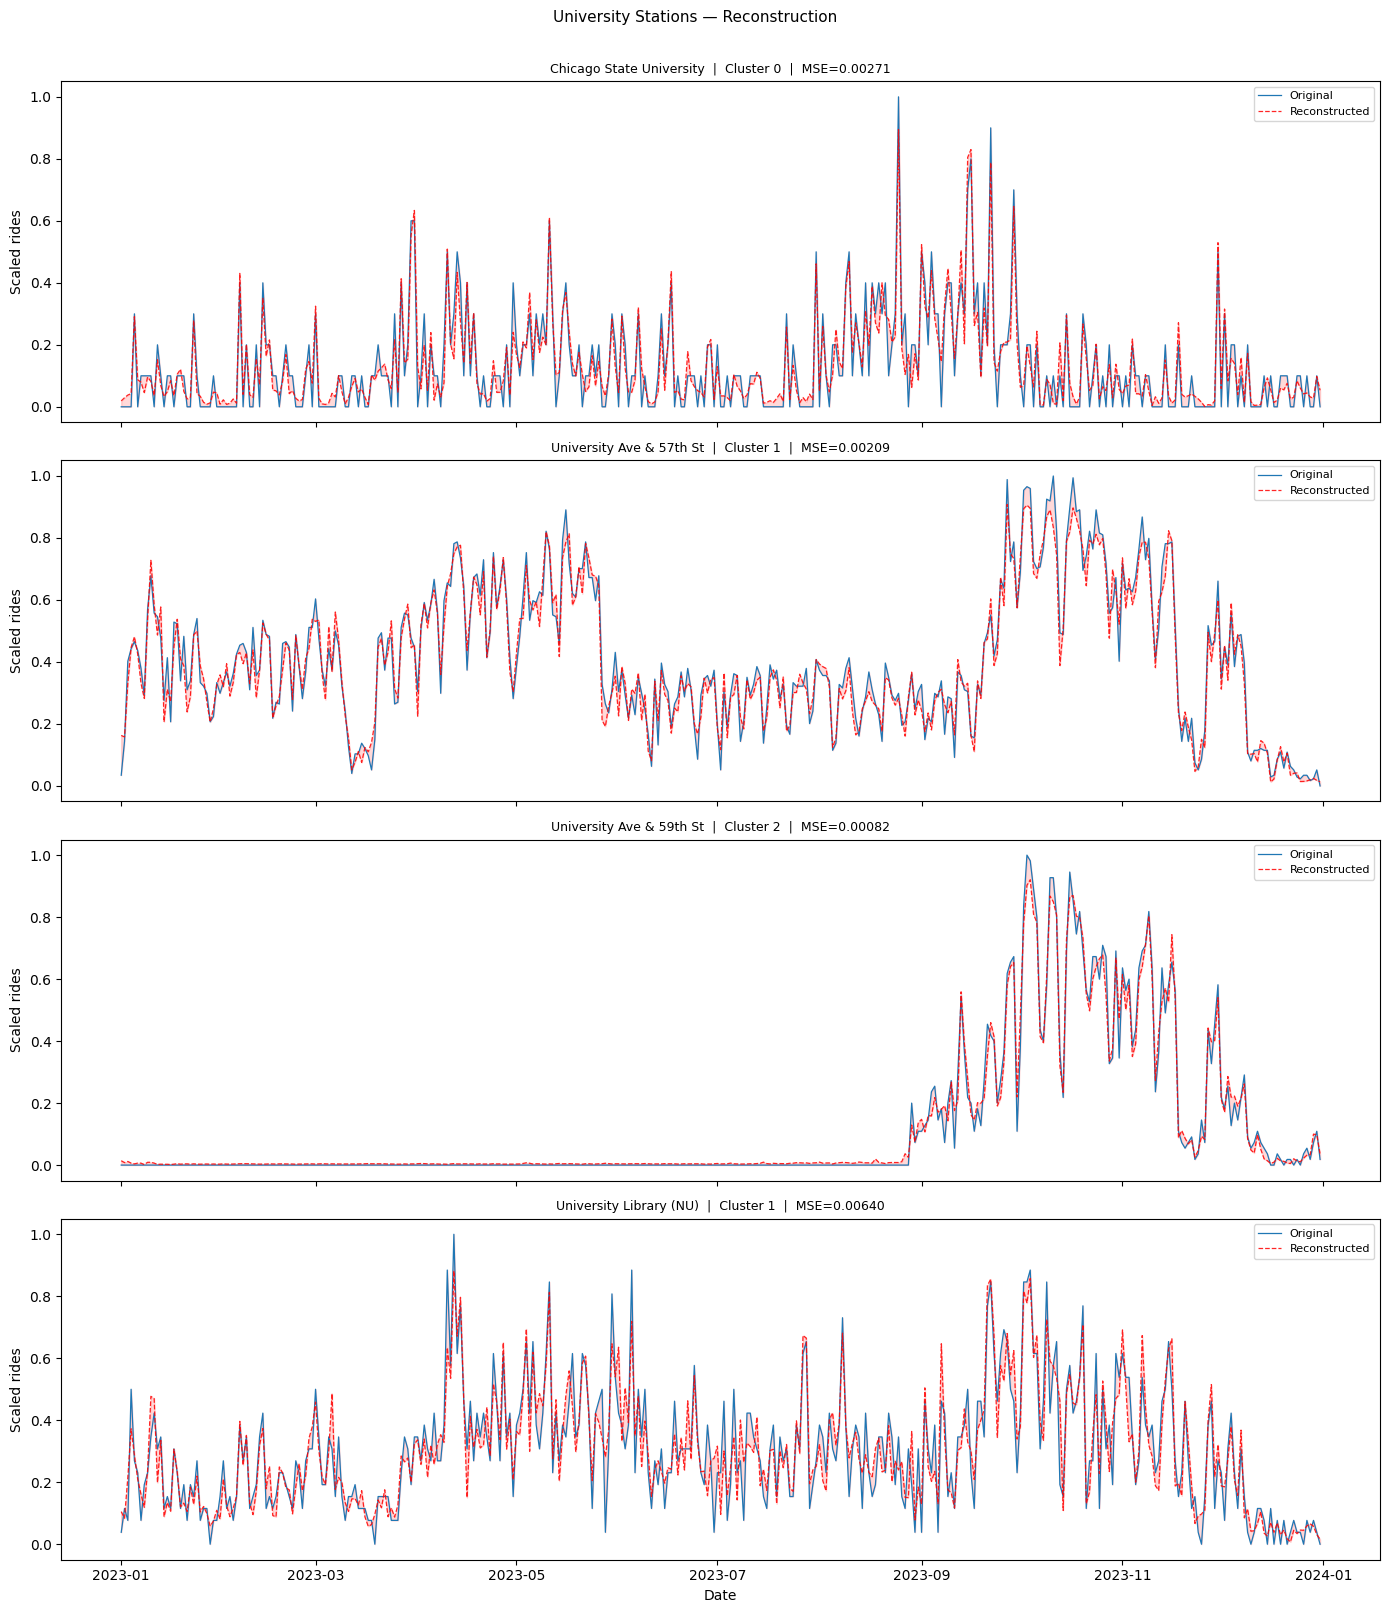

In [ ]:
fig, axes = plt.subplots(len(uni_idx), 1, figsize=(14, 4 * len(uni_idx)), sharex=True)
if len(uni_idx) == 1:
    axes = [axes]

for ax, idx in zip(axes, uni_idx):
    orig  = X[idx, 0, :]
    recon = X_recon[idx, 0, :]
    mse   = np.mean((orig - recon) ** 2)
    cluster_id = clusters[idx]

    ax.plot(dates, orig,  linewidth=0.9, label='Original')
    ax.plot(dates, recon, linewidth=0.9, linestyle='--', color='red', alpha=0.85, label='Reconstructed')
    ax.fill_between(dates, orig, recon, alpha=0.15, color='red')
    ax.set_title(f'{pivot.index[idx]}  |  Cluster {cluster_id}  |  MSE={mse:.5f}', fontsize=9)
    ax.set_ylabel('Scaled rides')
    ax.legend(fontsize=8)

axes[-1].set_xlabel('Date')
fig.suptitle('University Stations — Reconstruction', fontsize=11, y=1.005)
plt.tight_layout()
plt.show()

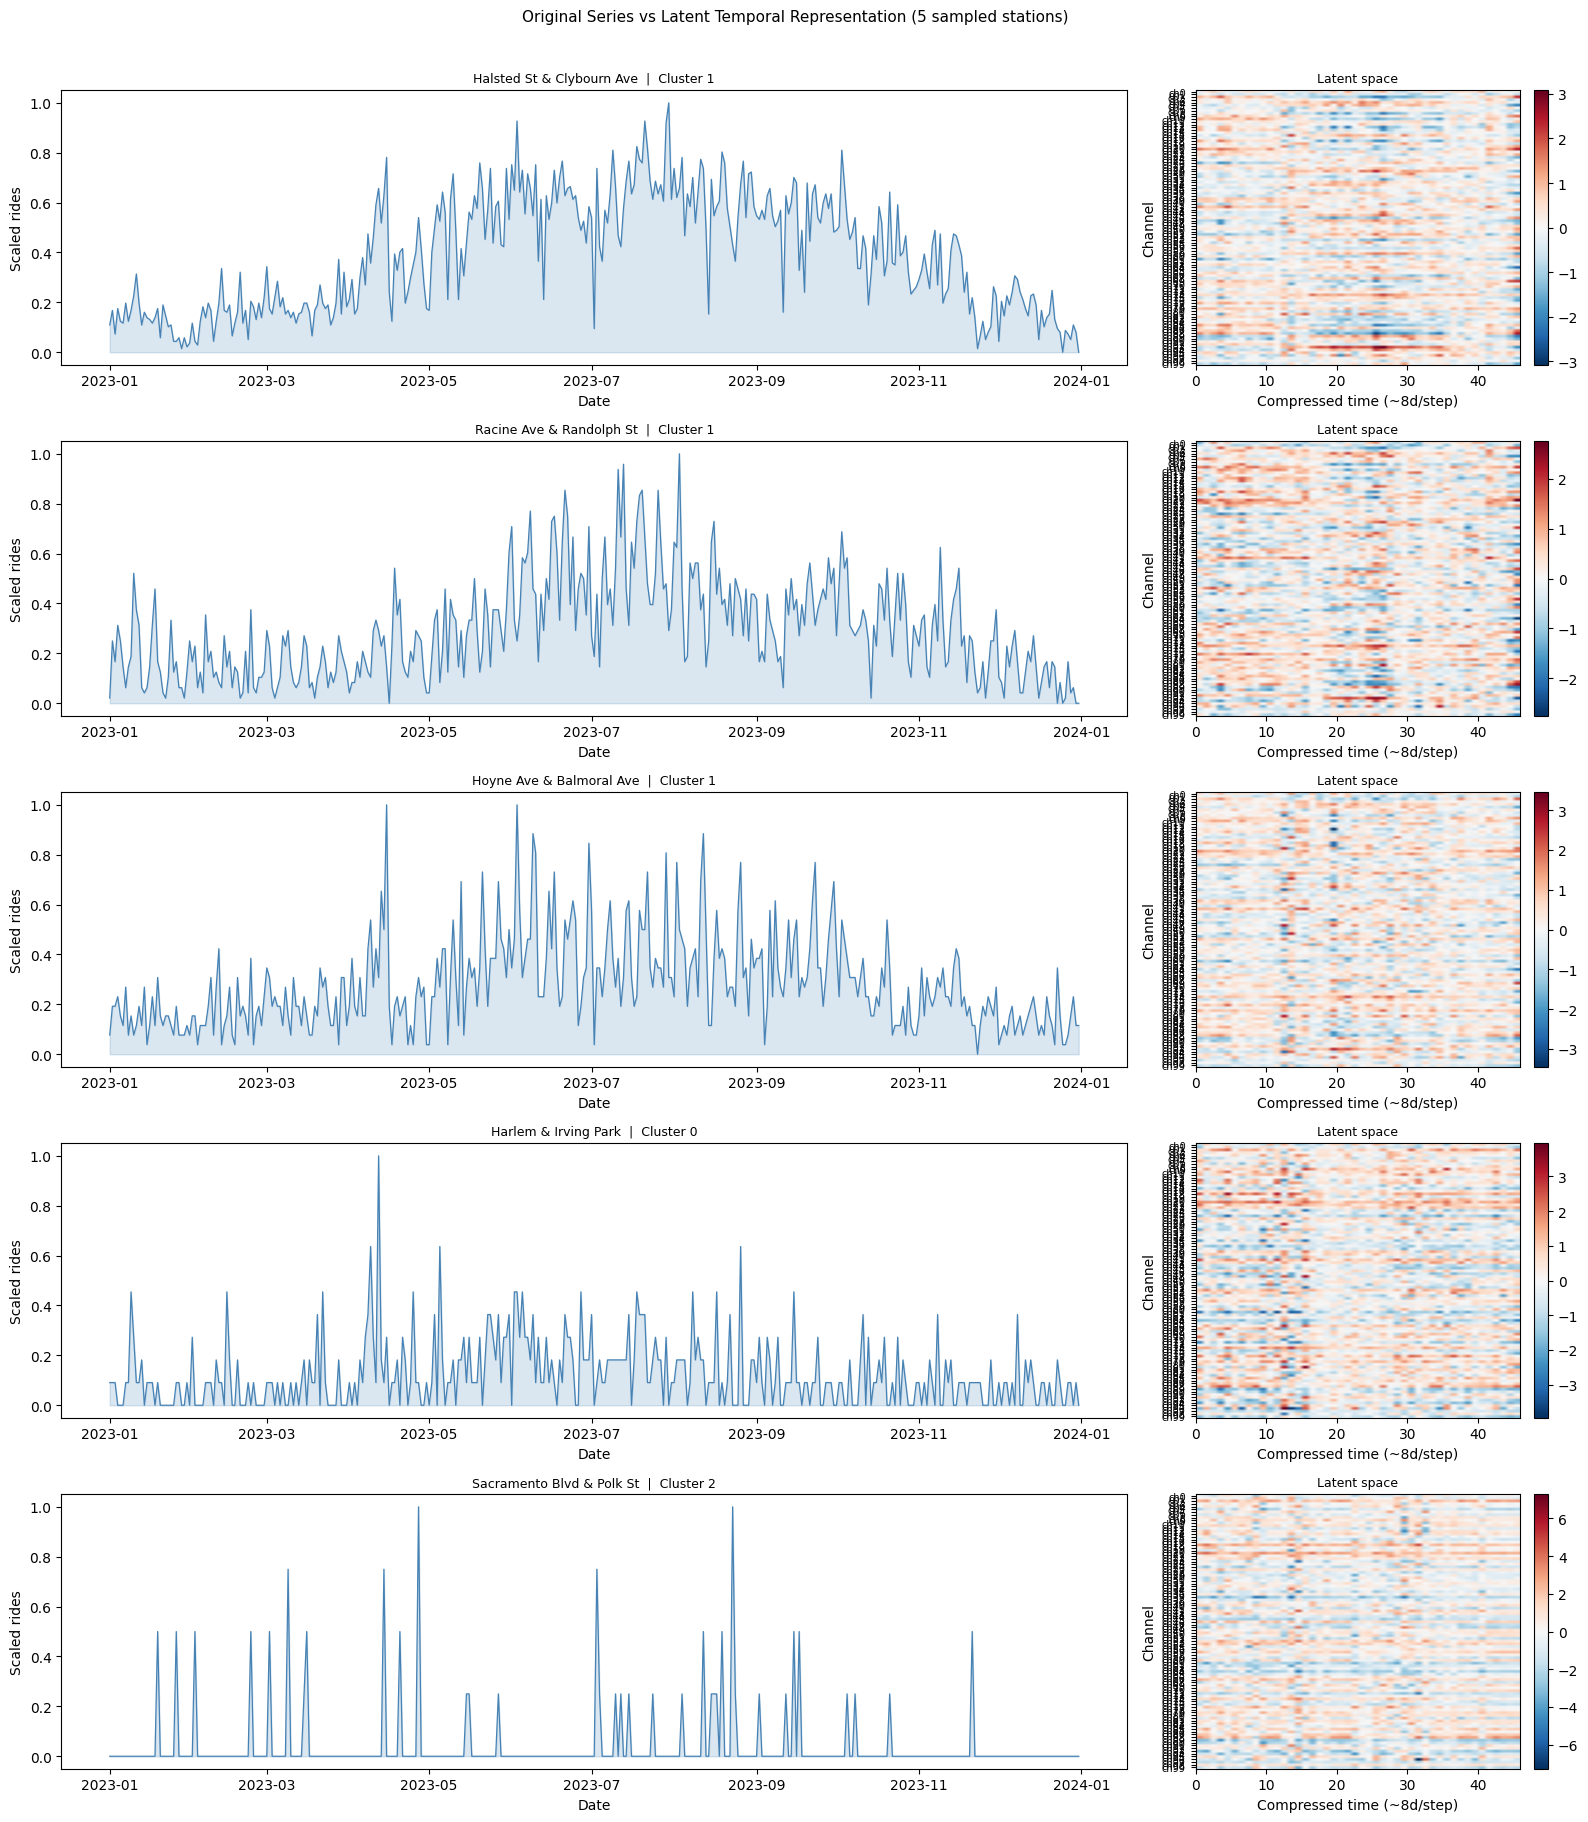

In [ ]:
# Sample 5 stations and visualize original series + latent temporal representation
np.random.seed(7)
sample_idx = np.random.choice(len(pivot), 5, replace=False)

# latent time axis — 46 compressed steps mapped back to approximate dates
T_latent   = Z_temporal.shape[2]  # 46
latent_dates = pd.date_range(dates[0], dates[-1], periods=T_latent)

fig, axes = plt.subplots(5, 2, figsize=(16, 18),
                          gridspec_kw={'width_ratios': [3, 1]})

for row, idx in enumerate(sample_idx):
    station_name = pivot.index[idx]
    cluster_id   = clusters[idx]

    # --- Left: original 365-day series ---
    ax_orig = axes[row, 0]
    ax_orig.plot(dates, X[idx, 0, :], linewidth=0.9, color='steelblue')
    ax_orig.fill_between(dates, X[idx, 0, :], alpha=0.2, color='steelblue')
    ax_orig.set_title(f'{station_name}  |  Cluster {cluster_id}', fontsize=9)
    ax_orig.set_ylabel('Scaled rides')
    ax_orig.set_xlabel('Date')

    # --- Right: latent temporal channels as heatmap (latent_channels x T_latent) ---
    ax_lat = axes[row, 1]
    z = Z_temporal[idx]  # (latent_channels, T_latent)
    im = ax_lat.imshow(z, aspect='auto', cmap='RdBu_r',
                       vmin=-np.abs(z).max(), vmax=np.abs(z).max(),
                       extent=[0, T_latent, z.shape[0], 0])
    ax_lat.set_title('Latent space', fontsize=9)
    ax_lat.set_xlabel('Compressed time (~8d/step)')
    ax_lat.set_ylabel('Channel')
    ax_lat.set_yticks(np.arange(z.shape[0]) + 0.5)
    ax_lat.set_yticklabels([f'ch{i}' for i in range(z.shape[0])], fontsize=7)
    plt.colorbar(im, ax=ax_lat, fraction=0.046, pad=0.04)

fig.suptitle('Original Series vs Latent Temporal Representation (5 sampled stations)',
             fontsize=11, y=1.01)
plt.tight_layout()
plt.show()


University stations: 4


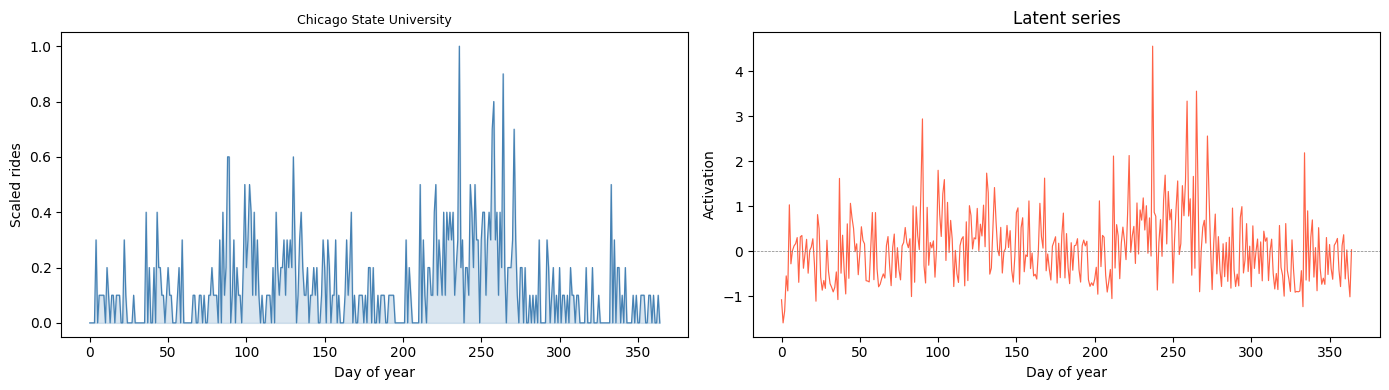

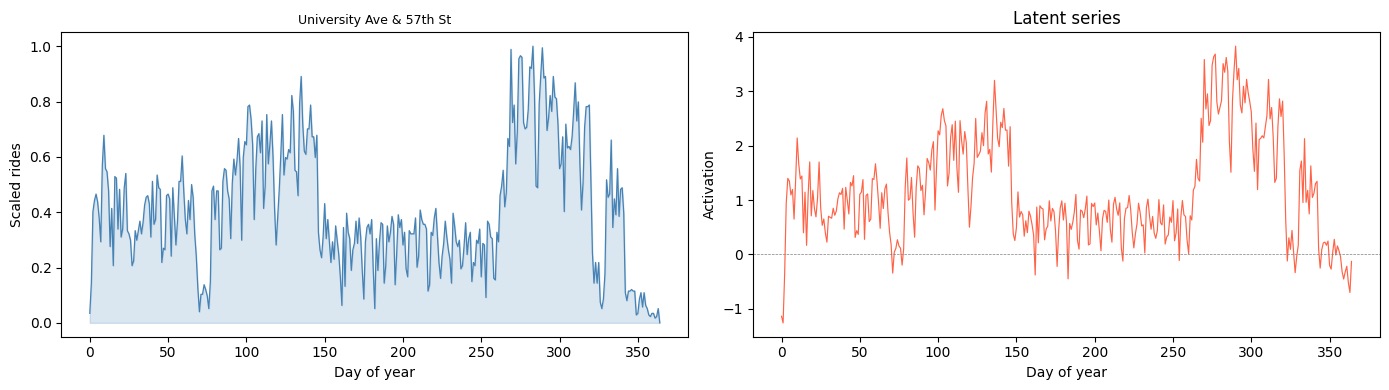

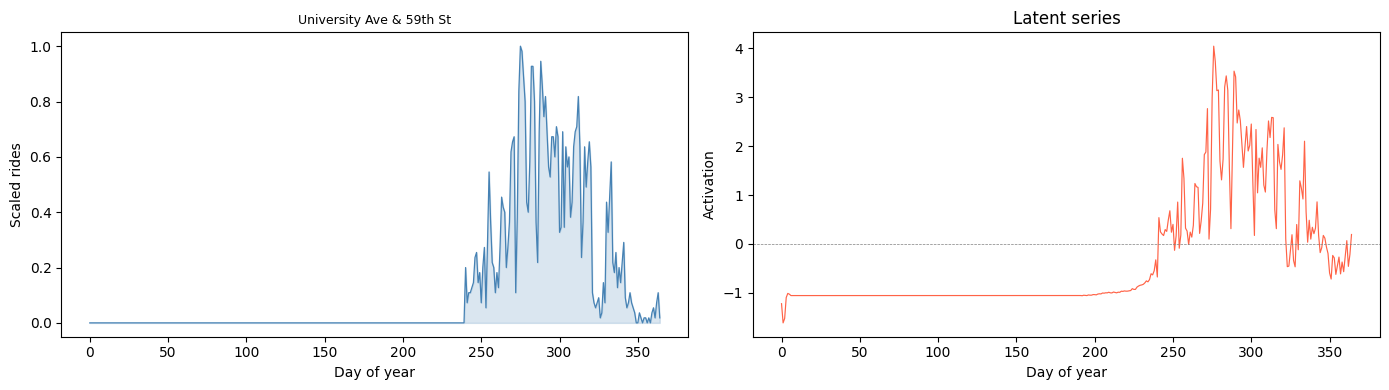

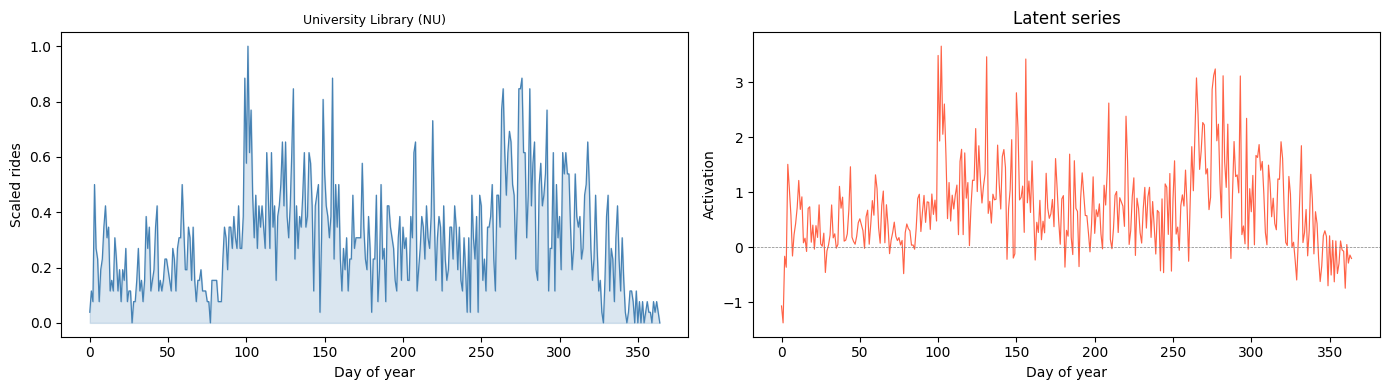

In [ ]:
# University stations — original vs latent
uni_idx = np.where(pd.Series(pivot.index).str.contains('University', case=False).values)[0]
t = np.arange(SEQ_LEN)

print(f'University stations: {len(uni_idx)}')
for idx in uni_idx:
    orig = X[idx, 0, :]
    z    = Z_temporal[idx]

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))

    ax1.plot(np.arange(SEQ_LEN), orig, linewidth=0.9, color='steelblue')
    ax1.fill_between(np.arange(SEQ_LEN), orig, alpha=0.2, color='steelblue')
    ax1.set_title(pivot.index[idx], fontsize=9)
    ax1.set_ylabel('Scaled rides')
    ax1.set_xlabel('Day of year')

    ax2.plot(np.arange(len(z[0])), z[0], linewidth=0.85, color='tomato')
    ax2.axhline(0, color='gray', linewidth=0.5, linestyle='--')
    ax2.set_title('Latent series')
    ax2.set_ylabel('Activation')
    ax2.set_xlabel('Day of year')

    plt.tight_layout()
    plt.show()
